# Evaluación Grupal del Proyecto de Minería de Datos

## Clasificación de viviendas según el acceso a servicios básicos en Bolivia

### Datos generales

**Grupo:** Sillita de Papel

**Tema del proyecto:** Clasificación de viviendas según el acceso a servicios básicos en Bolivia mediante técnicas de minería de datos.

**Asignatura:** Minería de Datos

**Docente:** Ing. Enrique Alejandro Laurel Cossio

### Integrantes

1. Gabriel Alexander Amistoy Aliaga
2. Agustin Alvaro Cruz Mamani
3. Daen Jonathan Callisaya Choque
4. Jhosmar Orlando Fer rufino Gutierrez
5. Saymon Agustin Perez Huanca
6. Jonathan San Martin San Martin
7. Paul Alejandro Rojas Araoz

### Descripción del proyecto

Este trabajo aplica las fases de entendimiento del negocio, entendimiento y preparación de los datos, y modelado de CRISP-DM a los microdatos de vivienda del Censo de Población y Vivienda 2024 del Instituto Nacional de Estadística (INE) de Bolivia. Las diez respuestas se apoyan en cálculos ejecutados en este notebook. El Índice de Precariedad de Servicios (IPS) y la clase de vivienda precaria son definiciones operativas del proyecto, no indicadores oficiales del INE.

---

### Pregunta 1. ¿Qué problema concreto aborda su proyecto, qué decisión o acción busca apoyar y cuál es su criterio de éxito de negocio? Indiquen a quién afecta y cómo se conecta el análisis con esa necesidad.

#### Respuesta

El problema es identificar viviendas con carencias simultáneas en agua, saneamiento, electricidad e internet. Afecta a quienes habitan esas viviendas y a los territorios donde se concentran. El análisis puede apoyar la **priorización de diagnósticos e intervenciones públicas**; no demuestra que una intervención haya mejorado servicios. El criterio de éxito de negocio es disponer de una identificación reproducible de viviendas y áreas con mayor precariedad, con cobertura y límites explícitos. La posibilidad de reducir la precariedad requeriría evaluar acciones posteriores.

| Problema | Necesidad de información | Indicador | Decisión que puede apoyar |
|---|---|---|---|
| Carencias simultáneas en servicios | Saber cuántas viviendas son clasificables y dónde se concentran | IPS y cobertura de las cuatro dimensiones | Priorizar revisión territorial y diagnóstico de servicios |

#### Procedimiento y evidencia

Se carga el archivo oficial y se aplican los filtros del proyecto. El conteo de registros con cuatro dimensiones clasificables se comprueba posteriormente al construir la clase.

In [1]:
from pathlib import Path
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"font.size":10, "axes.titlesize":12, "figure.dpi":110})
FUENTE = "Fuente: elaboración propia con microdatos del Censo 2024, INE Bolivia."
FUENTE_PRUEBA = "Fuente: elaboración propia. Prueba reservada; microdatos del Censo 2024, INE Bolivia."
CSV = Path("data/Vivienda_CPV-2024.csv")
DICT = Path("data/Diccionario de variables CPV 2024.xlsx")
assert CSV.is_file() and DICT.is_file()
predictoras = ["urbrur","v01_tipoviv","v03_pared","v05_techo","v06_piso",
               "v11_basura","v13_habitac","v14_dormit","v17_tenencia","tip_hog"]
fuentes_objetivo = ["v07_aguapro","v15_servsan","v16_desague","v09_energia","v19e_f"]
columnas_csv = pd.read_csv(CSV, sep=";", encoding="utf-8-sig", nrows=0).columns.tolist()
df = pd.read_csv(CSV, sep=";", encoding="utf-8-sig",
                 dtype={col:"category" for col in columnas_csv})
assert df.shape == (4_490_488,48)
particular = df["v01_tipoviv"].astype("string").isin({"1","2","3","4","5","6"})
presente = df["v02_condocup"].astype("string").isin({"0","1"})
personas = pd.to_numeric(df["tot_pers"].astype("string"),errors="coerce").gt(0)
aplica = df[["v07_aguapro","v15_servsan","v09_energia","v19e_f"]].notna().all(axis=1)
mascara_analitica = particular & presente & personas & aplica
columnas_analiticas = list(dict.fromkeys(predictoras+fuentes_objetivo))
df_analisis = df.loc[mascara_analitica,columnas_analiticas].copy()
assert len(df_analisis) == 3_623_711

agua = df_analisis["v07_aguapro"].astype("string")
san = df_analisis["v15_servsan"].astype("string")
des = df_analisis["v16_desague"].astype("string")
elec = df_analisis["v09_energia"].astype("string")
inet = df_analisis["v19e_f"].astype("string")
clasificable = (agua.isin({"1","2","4","5","6","7"}) &
               (san.isin({"2","3"}) | ((san=="1") & des.isin({"1","2","5","6"}))) &
               elec.isin({"1","2","3","4","5"}) & inet.isin({"1","2"}))
resumen_inicial = pd.DataFrame({
    "Población":["CSV original","Viviendas analíticas","Cuatro dimensiones clasificables"],
    "Viviendas":[len(df),len(df_analisis),int(clasificable.sum())]})
display(resumen_inicial)
assert int(clasificable.sum()) == 2_635_157
del particular,presente,personas,aplica,mascara_analitica,agua,san,des,elec,inet
gc.collect()

,Población,Viviendas
0,CSV original,4490488
1,Viviendas analíticas,3623711
2,Cuatro dimensiones clasificables,2635157


16

#### Resultados e interpretación

El conteo distingue el archivo original, la población analítica y las viviendas para las que pueden evaluarse las cuatro dimensiones. La decisión territorial debe considerar esta cobertura: una vivienda no clasificable no equivale a una vivienda sin carencias.

### Pregunta 2. ¿Cuál es la métrica principal del proyecto y cómo se calcula? Presenten su fórmula, las variables y unidades involucradas, el valor observado hasta ahora y una acción concreta para mejorarla. Aclaren si es una métrica de negocio o de desempeño del modelo.

#### Respuesta

La métrica de negocio es el **Índice de Precariedad de Servicios (IPS)**, medido en porcentaje de viviendas válidas para las cuatro dimensiones:

$$\mathrm{IPS}=\frac{V_{\geq 2}}{V_{\mathrm{validas}}}\times 100,$$

donde $V_{\geq 2}$ es el número de viviendas con dos o más carencias y $V_{\mathrm{validas}}$ el número con agua, saneamiento, electricidad e internet clasificables. Cada carencia vale 1 si existe privación según las reglas del proyecto y 0 si no; `n_carencias` suma las cuatro y `vivienda_precaria=1` cuando la suma es al menos 2. El IPS describe la población observada; **accuracy, F1 y ROC-AUC** evalúan predicciones del modelo.

#### Procedimiento y evidencia

Se reproducen las reglas documentadas en `entendimiento de datos.ipynb`. Los códigos ambiguos conservan valor indeterminado; se excluyen del denominador del IPS sin imputarlos.

,Viviendas,Porcentaje
Carencias,,
0,1377478,52.27
1,741185,28.13
2,302390,11.48
3,145921,5.54
4,68183,2.59


IPS nacional: 19.60% | Cobertura entre viviendas analíticas: 72.72%


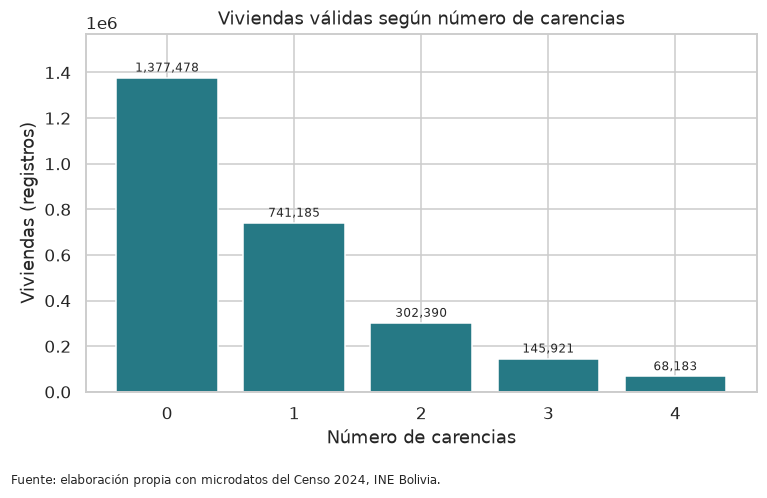

280

In [2]:
def indicador(index, reglas):
    resultado = pd.Series(pd.NA,index=index,dtype="Int8")
    for condicion,valor in reglas:
        resultado.loc[condicion.fillna(False)] = valor
    return resultado

agua = df_analisis["v07_aguapro"].astype("string")
san = df_analisis["v15_servsan"].astype("string")
des = df_analisis["v16_desague"].astype("string")
elec = df_analisis["v09_energia"].astype("string")
inet = df_analisis["v19e_f"].astype("string")
df_analisis["carencia_agua"] = indicador(df_analisis.index,[
    (agua.isin({"1","2","4","6"}),0),(agua.isin({"5","7"}),1)])
df_analisis["carencia_saneamiento"] = indicador(df_analisis.index,[
    ((san=="1") & des.isin({"1","2","6"}),0),
    (san.isin({"2","3"}) | ((san=="1") & (des=="5")),1)])
df_analisis["carencia_electricidad"] = indicador(df_analisis.index,[
    (elec.isin({"1","2","3","4"}),0),(elec=="5",1)])
df_analisis["carencia_internet"] = indicador(df_analisis.index,[
    (inet=="1",0),(inet=="2",1)])
carencias = ["carencia_agua","carencia_saneamiento","carencia_electricidad","carencia_internet"]
validas = df_analisis[carencias].notna().all(axis=1)
assert np.array_equal(validas.to_numpy(dtype=bool),
                      clasificable.to_numpy(dtype=bool,na_value=False))
df_objetivo = df_analisis.loc[validas,predictoras+carencias].copy()
df_objetivo["n_carencias"] = df_objetivo[carencias].sum(axis=1).astype("int8")
df_objetivo["vivienda_precaria"] = (df_objetivo["n_carencias"]>=2).astype("int8")
N_analitico,N_valido = len(df_analisis),len(df_objetivo)
IPS = 100*df_objetivo["vivienda_precaria"].mean()
cobertura = 100*N_valido/N_analitico
tabla_carencias = df_objetivo["n_carencias"].value_counts().reindex(range(5),fill_value=0).sort_index().rename_axis("Carencias").to_frame("Viviendas")
tabla_carencias["Porcentaje"] = 100*tabla_carencias["Viviendas"]/N_valido
display(tabla_carencias.round(2))
print(f"IPS nacional: {IPS:.2f}% | Cobertura entre viviendas analíticas: {cobertura:.2f}%")
assert len(df_objetivo)==2_635_157 and round(IPS,2)==19.60
fig,ax=plt.subplots(figsize=(7,4.5))
barras=ax.bar(tabla_carencias.index.astype(str),tabla_carencias["Viviendas"],color="#267985")
ax.bar_label(barras,labels=[f"{x:,}" for x in tabla_carencias["Viviendas"]],padding=2,fontsize=8)
ax.set(title="Viviendas válidas según número de carencias",xlabel="Número de carencias",ylabel="Viviendas (registros)")
ax.set_ylim(0,tabla_carencias["Viviendas"].max()*1.14)
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()
del agua,san,des,elec,inet
gc.collect()

#### Interpretación

El IPS calculado indica la proporción de viviendas **clasificables** con al menos dos carencias. Una acción propuesta sería priorizar un diagnóstico de saneamiento en territorios con IPS alto y cobertura suficiente; el notebook no mide aún el efecto de esa acción.

### Pregunta 3. ¿Cuál es la unidad de análisis, de dónde provienen los datos y cuántos registros y variables tiene el conjunto utilizado? Indiquen qué representa una fila y, si hubo filtros, cuántos registros quedaron después de aplicarlos.

#### Respuesta

La unidad de análisis es el **registro de vivienda** del archivo `Vivienda_CPV-2024.csv`, no una persona. Cada fila contiene respuestas censales y atributos de una vivienda. La fuente es el INE Bolivia, Censo de Población y Vivienda 2024. Las variables relevantes son las cinco preguntas que determinan las cuatro carencias, las diez características seleccionadas como predictores y los campos usados para filtrar la población.

#### Procedimiento y evidencia

La forma e información del `DataFrame` original se muestran directamente. La población analítica conserva viviendas particulares de tipos 1–6, ocupadas con personas presentes (`v02_condocup` 0/1), `tot_pers>0` y preguntas básicas aplicables. La población clasificable exige además cuatro carencias definidas.

df.shape: (4490488, 48)
<class 'pandas.DataFrame'>
RangeIndex: 4490488 entries, 0 to 4490487
Data columns (total 48 columns):
 #   Column          Dtype   
---  ------          -----   
 0   idep            category
 1   iprov           category
 2   imun            category
 3   i00             category
 4   urbrur          category
 5   v01_tipoviv     category
 6   v02_condocup    category
 7   v03_pared       category
 8   v04_revoq       category
 9   v05_techo       category
 10  v06_piso        category
 11  v07_aguapro     category
 12  v08_aguadist    category
 13  v09_energia     category
 14  v10_combus      category
 15  v11_basura      category
 16  v12_cocina      category
 17  v13_habitac     category
 18  v14_dormit      category
 19  v15_servsan     category
 20  v16_desague     category
 21  v17_tenencia    category
 22  v18a_bici       category
 23  v18b_moto       category
 24  v18c_auto       category
 25  v18d_carreta    category
 26  v18e_bote       category
 27 

,Etapa,Registros,Porcentaje del total
0,CSV original (48 variables),4490488,100.00
1,Población analítica,3623711,80.70
2,Válidas para IPS y modelado,2635157,58.68


Variables de servicio: ['v07_aguapro', 'v15_servsan', 'v16_desague', 'v09_energia', 'v19e_f']
Predictores: ['urbrur', 'v01_tipoviv', 'v03_pared', 'v05_techo', 'v06_piso', 'v11_basura', 'v13_habitac', 'v14_dormit', 'v17_tenencia', 'tip_hog']


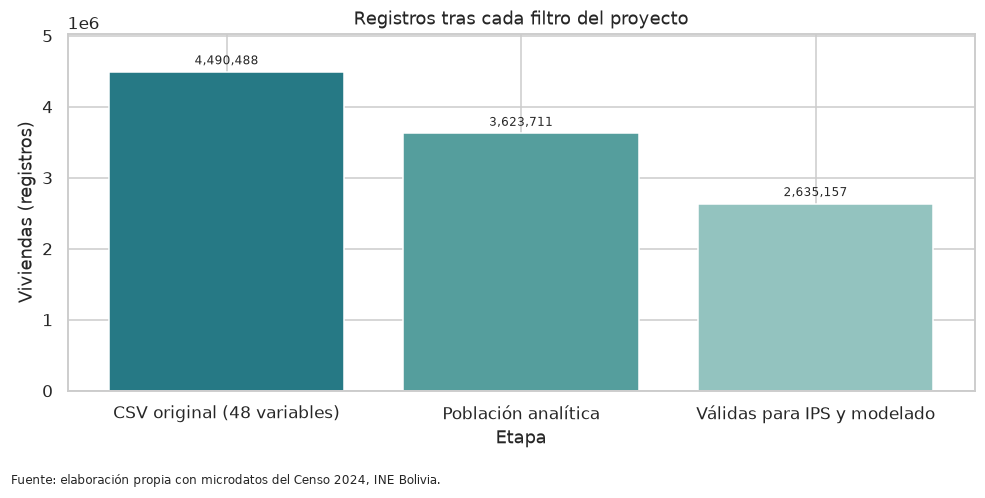

In [3]:
print("df.shape:",df.shape)
df.info()
etapas=pd.DataFrame({"Etapa":["CSV original (48 variables)","Población analítica","Válidas para IPS y modelado"],
                     "Registros":[len(df),N_analitico,N_valido]})
etapas["Porcentaje del total"] = 100*etapas["Registros"]/len(df)
display(etapas.round(2))
print("Variables de servicio:",fuentes_objetivo)
print("Predictores:",predictoras)
fig,ax=plt.subplots(figsize=(9,4.5))
barras=ax.bar(etapas["Etapa"],etapas["Registros"],color=["#267985","#559e9d","#93c3bf"])
ax.bar_label(barras,labels=[f"{v:,}" for v in etapas["Registros"]],padding=3,fontsize=8)
ax.set(title="Registros tras cada filtro del proyecto",xlabel="Etapa",ylabel="Viviendas (registros)")
ax.set_ylim(0,len(df)*1.12)
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()

#### Interpretación

La reducción de filas responde a la unidad y las preguntas pertinentes para el análisis. Los registros sin información suficiente para clasificar las cuatro dimensiones se conservan en el conteo analítico, pero no reciben IPS ni clase para modelado.

### Pregunta 4. ¿Qué problemas de calidad encontraron y qué preparación aplicaron? Informen la cantidad y las columnas con valores faltantes; mencionen también duplicados o inconsistencias relevantes y expliquen qué hicieron y por qué.

#### Respuesta

Se distinguen celdas vacías, respuestas con códigos especiales y saltos lógicos del cuestionario. No todo vacío es un error: por ejemplo, el destino del desagüe no se pregunta cuando la vivienda no tiene baño. Los códigos de fuente de agua que no permiten asignar carencia con la regla adoptada y las respuestas de internet no clasificables quedan indeterminados. No se imputan carencias ni se interpreta ausencia de respuesta como acceso. La construcción reproducible de las cuatro carencias aparece en la pregunta 2.

#### Procedimiento y evidencia

,Columna,Nulos,Porcentaje
0,v20b_totemi,4187319,93.25
1,v21b_totfal,4145006,92.31
2,v16_desague,1601034,35.65
3,v03_pared,866777,19.30
4,v07_aguapro,866777,19.30
5,v10_combus,866777,19.30
6,v09_energia,866777,19.30
7,v08_aguadist,866777,19.30
8,v11_basura,866777,19.30
9,v14_dormit,866777,19.30


Columnas con nulos: 41
Nulos por columna (tabla completa):


,Columna,Nulos,Porcentaje
0,v20b_totemi,4187319,93.25
1,v21b_totfal,4145006,92.31
2,v16_desague,1601034,35.65
3,v03_pared,866777,19.30
4,v07_aguapro,866777,19.30
5,v10_combus,866777,19.30
6,v09_energia,866777,19.30
7,v08_aguadist,866777,19.30
8,v11_basura,866777,19.30
9,v14_dormit,866777,19.30


Identificadores i00 repetidos: 0 | i00 vacíos: 0 | Filas completas duplicadas: 0


,Situación,Viviendas,Porcentaje analítico
0,Sin baño y desagüe vacío (salto lógico),734257,20.26
1,Sin baño pero desagüe informado (inconsistencia),0,0.00
2,"Agua: códigos 3, 8 o 9 (indeterminados)",239177,6.60
3,Internet: código 9 (respuesta especial),131692,3.63
4,Registros analíticos no clasificables,988554,27.28


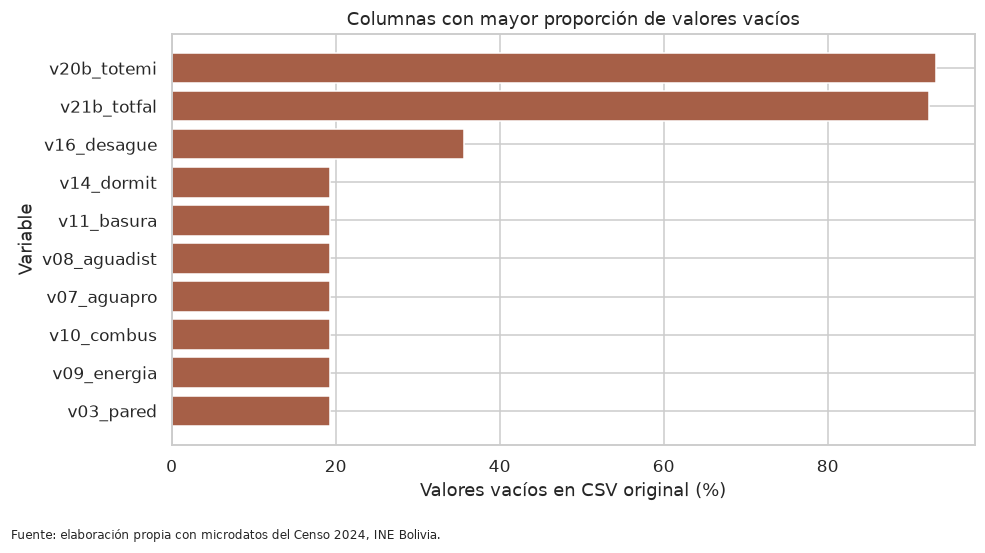

Nulos en predictores de la población modelada: 0


3683

In [4]:
nulos=df.isna().sum().sort_values(ascending=False)
tabla_nulos=pd.DataFrame({"Columna":nulos.index,"Nulos":nulos.values,
                           "Porcentaje":100*nulos.values/len(df)})
display(tabla_nulos.loc[tabla_nulos["Nulos"]>0].head(20).round(2))
print("Columnas con nulos:",int((nulos>0).sum()))
print("Nulos por columna (tabla completa):")
display(tabla_nulos.round(2))
duplicados_i00=int(df["i00"].duplicated().sum())
nulos_i00=int(df["i00"].isna().sum())
duplicados_exactos=(0 if duplicados_i00==0 and nulos_i00==0
                    else int(df.duplicated().sum()))
print("Identificadores i00 repetidos:",duplicados_i00,
      "| i00 vacíos:",nulos_i00,"| Filas completas duplicadas:",duplicados_exactos)
sin_bano=df_analisis["v15_servsan"].astype("string").eq("3")
desague_vacio=df_analisis["v16_desague"].isna()
agua_ambigua=df_analisis["v07_aguapro"].astype("string").isin({"3","8","9"})
internet_especial=df_analisis["v19e_f"].astype("string").eq("9")
calidad=pd.DataFrame({"Situación":["Sin baño y desagüe vacío (salto lógico)",
                                   "Sin baño pero desagüe informado (inconsistencia)",
                                   "Agua: códigos 3, 8 o 9 (indeterminados)",
                                   "Internet: código 9 (respuesta especial)",
                                   "Registros analíticos no clasificables"],
                      "Viviendas":[int((sin_bano & desague_vacio).sum()),
                                   int((sin_bano & ~desague_vacio).sum()),
                                   int(agua_ambigua.sum()),int(internet_especial.sum()),
                                   int((~validas).sum())]})
calidad["Porcentaje analítico"] = 100*calidad["Viviendas"]/N_analitico
display(calidad.round(2))
fig,ax=plt.subplots(figsize=(9,5))
top_nulos=tabla_nulos.head(10).sort_values("Porcentaje")
ax.barh(top_nulos["Columna"],top_nulos["Porcentaje"],color="#a65f47")
ax.set(title="Columnas con mayor proporción de valores vacíos",xlabel="Valores vacíos en CSV original (%)",ylabel="Variable")
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()
faltantes_pred=df_objetivo[predictoras].isna().sum()
print("Nulos en predictores de la población modelada:",int(faltantes_pred.sum()))
assert faltantes_pred.eq(0).all()
del df,nulos,tabla_nulos,sin_bano,desague_vacio,agua_ambigua,internet_especial
gc.collect()

#### Interpretación

El identificador `i00` permite verificar unicidad: si no hay identificadores vacíos ni repetidos, tampoco puede existir una fila completa duplicada. Se informa por separado la frecuencia de códigos especiales y de vacíos. Las viviendas con una dimensión indeterminada no entran al denominador del IPS ni al entrenamiento. Los diez predictores elegidos no necesitan imputación en esa población.

### Pregunta 5. ¿Qué resultado interesante encontraron en la exploración y qué gráfico lo demuestra? Muéstrenlo con título y etiquetas, describan el patrón observado y expliquen por qué importa para el objetivo del proyecto.

#### Respuesta

Se compara el IPS entre áreas urbana y rural. Es una descripción de las viviendas **válidas** en cada área, no una relación causal. La cobertura se informa junto al índice porque una proporción distinta de registros queda sin clasificar en cada grupo.

#### Procedimiento y evidencia

,Área,N_analitica,N_validas,Cobertura_%,N_precarias,IPS_%
1,Rural,1236792,719000,58.13,414788,57.69
0,Urbana,2386919,1916157,80.28,101706,5.31


Diferencia rural - urbana: 52.38 puntos porcentuales


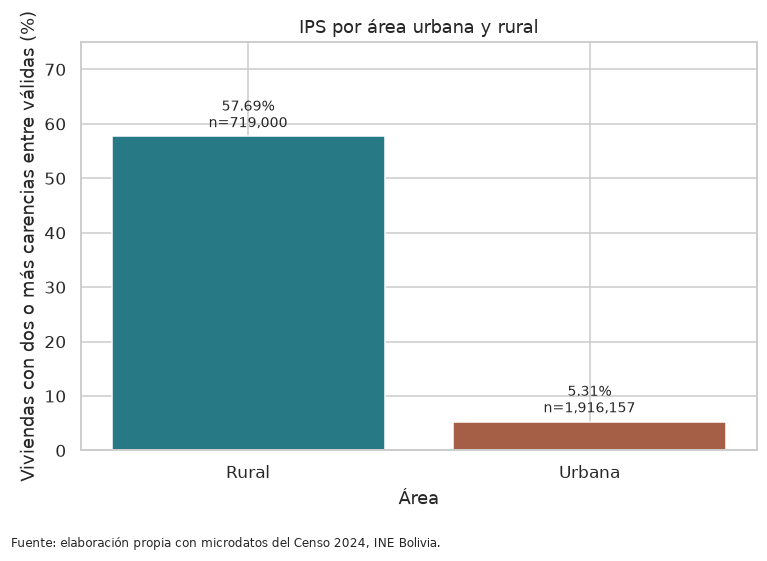

In [5]:
area_analitica=df_analisis.groupby("urbrur",observed=True).size().rename("N_analitica")
area_ips=df_objetivo.groupby("urbrur",observed=True).agg(
    N_validas=("vivienda_precaria","size"),N_precarias=("vivienda_precaria","sum"))
area_ips=area_ips.join(area_analitica)
area_ips["IPS_%"] = 100*area_ips["N_precarias"]/area_ips["N_validas"]
area_ips["Cobertura_%"] = 100*area_ips["N_validas"]/area_ips["N_analitica"]
area_ips["Área"] = area_ips.index.astype("string").map({"1":"Urbana","2":"Rural"})
area_ips=area_ips.reset_index(drop=True).sort_values("Área")
display(area_ips[["Área","N_analitica","N_validas","Cobertura_%","N_precarias","IPS_%"]].round(2))
urbano=float(area_ips.loc[area_ips["Área"]=="Urbana","IPS_%"].iloc[0])
rural=float(area_ips.loc[area_ips["Área"]=="Rural","IPS_%"].iloc[0])
dif_pp=rural-urbano
print(f"Diferencia rural - urbana: {dif_pp:.2f} puntos porcentuales")
fig,ax=plt.subplots(figsize=(7,5))
barras=ax.bar(area_ips["Área"],area_ips["IPS_%"],color=["#267985","#a65f47"])
etiquetas=[f"{r['IPS_%']:.2f}%\nn={int(r['N_validas']):,}" for _,r in area_ips.iterrows()]
ax.bar_label(barras,labels=etiquetas,padding=3,fontsize=9)
ax.set(title="IPS por área urbana y rural",xlabel="Área",ylabel="Viviendas con dos o más carencias entre válidas (%)",ylim=(0,75))
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()

In [6]:
cob_urb=float(area_ips.loc[area_ips["Área"]=="Urbana","Cobertura_%"].iloc[0])
cob_rur=float(area_ips.loc[area_ips["Área"]=="Rural","Cobertura_%"].iloc[0])
display(Markdown(
    f"#### Interpretación\n\nEl IPS rural es **{rural:.2f}%** y el urbano **{urbano:.2f}%**, "
    f"una diferencia descriptiva de **{dif_pp:.2f} puntos porcentuales**. "
    f"La cobertura es **{cob_rur:.2f}%** en el área rural y **{cob_urb:.2f}%** en la urbana. "
    "Por ello, la comparación describe únicamente los registros clasificables; "
    "las respuestas indeterminadas podrían afectar la comparación. El gráfico ayuda a priorizar "
    "un análisis territorial más detallado, sin demostrar que vivir en un área cause la carencia."
))

#### Interpretación

El IPS rural es **57.69%** y el urbano **5.31%**, una diferencia descriptiva de **52.38 puntos porcentuales**. La cobertura es **58.13%** en el área rural y **80.28%** en la urbana. Por ello, la comparación describe únicamente los registros clasificables; las respuestas indeterminadas podrían afectar la comparación. El gráfico ayuda a priorizar un análisis territorial más detallado, sin demostrar que vivir en un área cause la carencia.

### Pregunta 6. ¿Cuál es su variable objetivo para la clasificación, qué clases tiene y qué modelo revisado en clase utilizaron: regresión logística, árbol de decisión o ambos? Expliquen brevemente por qué ese modelo es pertinente para su problema.

#### Respuesta

La variable objetivo es **`vivienda_precaria`**: clase 0 para menos de dos carencias y clase 1 para dos o más. Se trata de clasificación binaria porque cada vivienda clasificable pertenece a una de esas dos clases. Se utilizan **regresión logística** y **árbol de decisión**, ambos revisados en clase. La primera ofrece coeficientes y una probabilidad estimada; el segundo expresa reglas de separación. Ninguno establece causalidad.

Para la regresión logística, $P(Y=1\mid X)=\dfrac{1}{1+e^{-z}}$, con $z=\beta_0+\sum_j\beta_jx_j$. El árbol compara divisiones que reducen la impureza de Gini $G=1-\sum_k p_k^2$.

#### Procedimiento y evidencia

La clase fue construida en la pregunta 2; aquí se verifica su distribución.

,Clase,Viviendas,Porcentaje
0,0: menos de dos carencias,2118663,80.4
1,1: dos o más carencias,516494,19.6


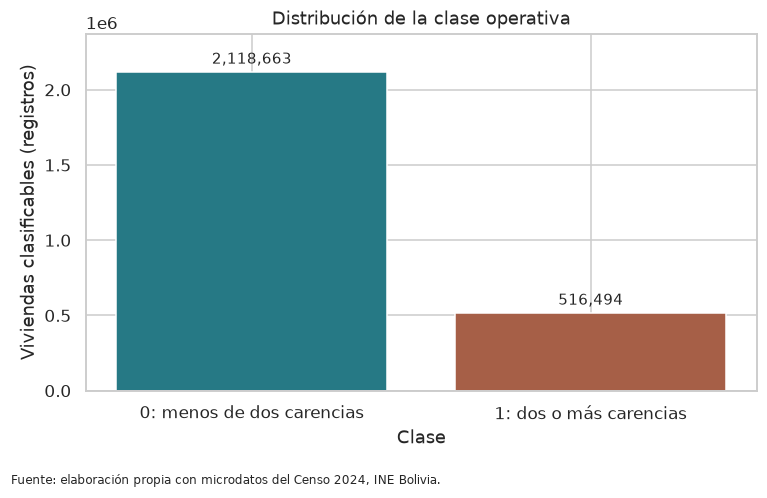

In [7]:
assert df_objetivo["vivienda_precaria"].equals(
    (df_objetivo[carencias].sum(axis=1)>=2).astype("int8"))
clases=df_objetivo["vivienda_precaria"].value_counts().reindex([0,1],fill_value=0)
tabla_clases=pd.DataFrame({"Clase":["0: menos de dos carencias","1: dos o más carencias"],
                           "Viviendas":clases.values,
                           "Porcentaje":100*clases.values/len(df_objetivo)})
display(tabla_clases.round(2))
fig,ax=plt.subplots(figsize=(7,4.5))
barras=ax.bar(tabla_clases["Clase"],tabla_clases["Viviendas"],color=["#267985","#a65f47"])
ax.bar_label(barras,labels=[f"{v:,}" for v in tabla_clases["Viviendas"]],padding=3)
ax.set(title="Distribución de la clase operativa",xlabel="Clase",ylabel="Viviendas clasificables (registros)")
ax.set_ylim(0,clases.max()*1.12)
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()

#### Interpretación

La clase 1 es minoritaria. Por ello, la exactitud global no basta para evaluar la capacidad de detectar viviendas con precariedad; también se examinan precision, recall y F1.

### Pregunta 7. ¿Qué proporción de los datos usaron para entrenamiento y para prueba, y cómo hicieron la separación? Indiquen el método o semilla si corresponde y cómo evitaron que información de prueba influyera en el entrenamiento o la preparación.

#### Respuesta

Se reserva el **20 %** para prueba y se usa el **80 %** para entrenamiento, con `random_state=42` y estratificación por clase. Así se conserva aproximadamente la proporción de viviendas precarias en ambos conjuntos. Los dos modelos usan exactamente los mismos índices de entrenamiento y prueba. La codificación se ajusta dentro de cada `Pipeline` únicamente cuando se entrena el modelo; la prueba solo se transforma con el codificador ya ajustado.

#### Procedimiento y evidencia

In [8]:
excluidas=set(fuentes_objetivo+carencias+["n_carencias","vivienda_precaria",
    "i00","idep","iprov","imun","v08_aguadist","v10_combus",
    "v19e_inetfijo","v19f_inetmovil"])
excluidas.update(c for c in columnas_csv if c.startswith(("v18","v19")))
assert not (set(predictoras)&excluidas)
X=df_objetivo[predictoras]
y=df_objetivo["vivienda_precaria"]
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.20,random_state=42,stratify=y)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train.index.intersection(X_test.index).empty
def preparar():
    return ColumnTransformer([
        ("categoricas",OneHotEncoder(handle_unknown="ignore",drop="first",
                                      sparse_output=True,dtype=np.float32),predictoras)
    ],sparse_threshold=1.0)
display(pd.DataFrame({"Conjunto":["Entrenamiento","Prueba"],
  "Registros":[len(y_train),len(y_test)],
  "Clase 0":[int((y_train==0).sum()),int((y_test==0).sum())],
  "Clase 1":[int((y_train==1).sum()),int((y_test==1).sum())],
  "Clase 1 (%)":[100*y_train.mean(),100*y_test.mean()]}).round(2))
print("Variables excluidas presentes en X:",set(X.columns)&excluidas)
print("Pipeline de preparación:",preparar())
assert len(X_train)==2_108_125 and len(X_test)==527_032

,Conjunto,Registros,Clase 0,Clase 1,Clase 1 (%)
0,Entrenamiento,2108125,1694930,413195,19.6
1,Prueba,527032,423733,103299,19.6


Variables excluidas presentes en X: set()
Pipeline de preparación: ColumnTransformer(sparse_threshold=1.0,
                  transformers=[('categoricas',
                                 OneHotEncoder(drop='first',
                                               dtype=<class 'numpy.float32'>,
                                               handle_unknown='ignore'),
                                 ['urbrur', 'v01_tipoviv', 'v03_pared',
                                  'v05_techo', 'v06_piso', 'v11_basura',
                                  'v13_habitac', 'v14_dormit', 'v17_tenencia',
                                  'tip_hog'])])


#### Interpretación

El codificador One-Hot omite una categoría de referencia por variable. El objetivo, sus cuatro componentes, preguntas que lo revelan directamente, identificadores y proxies cercanos quedan fuera de `X`. La misma partición se entrega a ambos `Pipeline`, por lo que no se comparan modelos sobre viviendas diferentes. La prueba no interviene en el ajuste de transformadores ni de parámetros.

### Pregunta 8. ¿Cuáles son las variables más importantes según su modelo y cómo determinaron su importancia? Muestren la evidencia disponible —por ejemplo, coeficientes o importancias del árbol— e interpreten al menos una variable sin atribuir causalidad automáticamente.

#### Respuesta

Se reentrenan aquí los **modelos finales documentados** en los notebooks individuales, con la misma población y partición. La regresión logística conservó `C=1`, `solver="liblinear"` y `class_weight="balanced"`; el árbol seleccionado por validación interna usa Gini, profundidad máxima 15, mínimo de 1.000 muestras por hoja y 2.000 por división. El ajuste de esos parámetros ocurrió en sus notebooks respectivos; este documento reproduce los modelos fijados y verifica su desempeño. No se eligen parámetros con la prueba.

Los coeficientes logísticos comparan una categoría con su referencia omitida. La importancia del árbol suma las reducciones ponderadas de impureza en las divisiones donde participa cada columna codificada. Ambas medidas describen el modelo, no efectos causales.

#### Procedimiento y evidencia

In [9]:
modelo_logistico=Pipeline([
    ("preprocesamiento",preparar()),
    ("clasificador",LogisticRegression(C=1.0,solver="liblinear",
        class_weight="balanced",max_iter=100,tol=1e-4,random_state=42))])
modelo_arbol=Pipeline([
    ("preprocesamiento",preparar()),
    ("clasificador",DecisionTreeClassifier(criterion="gini",max_depth=15,
        min_samples_leaf=1000,min_samples_split=2000,random_state=42))])
modelo_logistico.fit(X_train,y_train)
modelo_arbol.fit(X_train,y_train)
print("Logística: C=1, liblinear, class_weight=balanced")
print("Árbol: Gini, profundidad",modelo_arbol.named_steps["clasificador"].get_depth(),
      ", hojas",modelo_arbol.named_steps["clasificador"].get_n_leaves())
print("Índices de entrenamiento idénticos para ambos modelos:",
      X_train.index.equals(y_train.index))

Logística: C=1, liblinear, class_weight=balanced
Árbol: Gini, profundidad 15 , hojas 548
Índices de entrenamiento idénticos para ambos modelos: True


Coeficientes más positivos y negativos:


,Categoría codificada,Variable,Código,Categoría oficial,Coeficiente
26,categoricas__v11_basura_4,v11_basura,4,La botan al río,1.5128
28,categoricas__v11_basura_6,v11_basura,6,La entierran,1.3880
3,categoricas__v01_tipoviv_4,v01_tipoviv,4,Cuarto(s) o habitación(es) suelta(s),1.3879
27,categoricas__v11_basura_5,v11_basura,5,La queman,1.2338
29,categoricas__v11_basura_7,v11_basura,7,Otra forma,1.1728
25,categoricas__v11_basura_3,v11_basura,3,La botan en un terreno baldío o la calle,1.0905
0,categoricas__urbrur_2,urbrur,2,Rural,0.9969
2,categoricas__v01_tipoviv_3,v01_tipoviv,3,Departamento,-6.7103
18,categoricas__v06_piso_4,v06_piso,4,"Cerámica, porcelanato",-1.7969
17,categoricas__v06_piso_3,v06_piso,3,"Machimbre, parquet",-1.7902


,Variable,Código de referencia,Categoría oficial
0,urbrur,1,Urbana
1,v01_tipoviv,1,Casa
2,v03_pared,1,"Ladrillo, bloque de cemento, hormigón"
3,v05_techo,1,Calamina o plancha
4,v06_piso,1,Tierra
5,v11_basura,1,La depositan en el contenedor o basurero público
6,v13_habitac,1,Uno
7,v14_dormit,0,Cero
8,v17_tenencia,1,Propia y totalmente pagada
9,tip_hog,1,Hogar unipersonal


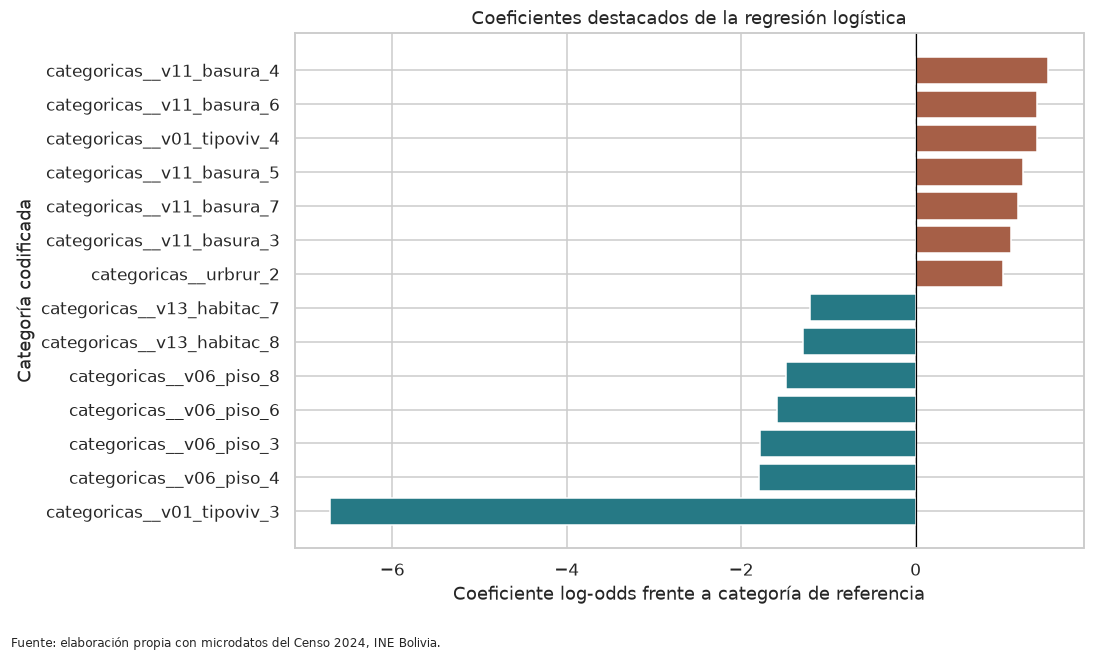

In [10]:
# Las etiquetas proceden de la hoja VIVIENDA del diccionario oficial.
tabla_dic=pd.read_excel(DICT,sheet_name="VIVIENDA",header=None,dtype="string")
fichas={}
descripcion,actual="",None
for fila_dic in tabla_dic.itertuples(index=False,name=None):
    clave=str(fila_dic[1]).strip() if pd.notna(fila_dic[1]) else ""
    dato=str(fila_dic[2]).strip() if pd.notna(fila_dic[2]) else ""
    if clave=="Etiqueta": descripcion=dato
    elif clave=="Nombre":
        actual=dato.lower()
        fichas[actual]={"descripcion":descripcion,"categorias":{}}
    elif actual is not None and clave not in ("","Categorías","Tipo") and pd.notna(fila_dic[2]):
        fichas[actual]["categorias"][clave]=dato

def descomponer_categoria(nombre):
    sin_prefijo=nombre.removeprefix("categoricas__")
    for variable in sorted(predictoras,key=len,reverse=True):
        if sin_prefijo.startswith(variable+"_"):
            codigo=sin_prefijo[len(variable)+1:]
            etiqueta=fichas[variable]["categorias"].get(codigo,"Sin etiqueta oficial")
            return variable,codigo,etiqueta
    raise ValueError(f"Categoría no reconocida: {nombre}")

pre_log=modelo_logistico.named_steps["preprocesamiento"]
nombres_log=pre_log.get_feature_names_out()
coefs=modelo_logistico.named_steps["clasificador"].coef_[0]
assert len(nombres_log)==len(coefs)
detalle=[descomponer_categoria(nombre) for nombre in nombres_log]
tabla_coef=pd.DataFrame({"Categoría codificada":nombres_log,
                         "Variable":[x[0] for x in detalle],
                         "Código":[x[1] for x in detalle],
                         "Categoría oficial":[x[2] for x in detalle],
                         "Coeficiente":coefs})
print("Coeficientes más positivos y negativos:")
display(pd.concat([tabla_coef.nlargest(7,"Coeficiente"),
                   tabla_coef.nsmallest(7,"Coeficiente")]).round(4))
referencias=pd.DataFrame({"Variable":predictoras,
  "Código de referencia":[str(c[0]) for c in pre_log.named_transformers_["categoricas"].categories_]})
referencias["Categoría oficial"]=[fichas[variable]["categorias"].get(codigo,"Sin etiqueta oficial")
    for variable,codigo in zip(referencias["Variable"],referencias["Código de referencia"])]
display(referencias)
destacados=pd.concat([tabla_coef.nlargest(7,"Coeficiente"),
                      tabla_coef.nsmallest(7,"Coeficiente")]).drop_duplicates()
destacados=destacados.sort_values("Coeficiente")
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(destacados["Categoría codificada"],destacados["Coeficiente"],
        color=np.where(destacados["Coeficiente"]>=0,"#a65f47","#267985"))
ax.axvline(0,color="black",linewidth=.8)
ax.set(title="Coeficientes destacados de la regresión logística",
       xlabel="Coeficiente log-odds frente a categoría de referencia",ylabel="Categoría codificada")
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()

,Categoría codificada,Importancia
0,categoricas__urbrur_2,0.70142
18,categoricas__v06_piso_4,0.08023
19,categoricas__v06_piso_5,0.07181
24,categoricas__v11_basura_2,0.02833
27,categoricas__v11_basura_5,0.01543
37,categoricas__v14_dormit_1,0.01400
14,categoricas__v05_techo_4,0.01249
3,categoricas__v01_tipoviv_4,0.01189
17,categoricas__v06_piso_3,0.00946
21,categoricas__v06_piso_7,0.00791


,Variable,Importancia
1,urbrur,0.70142
5,v06_piso,0.17473
6,v11_basura,0.04834
8,v14_dormit,0.02056
2,v01_tipoviv,0.01807
4,v05_techo,0.01480
0,tip_hog,0.00929
3,v03_pared,0.00641
9,v17_tenencia,0.00494
7,v13_habitac,0.00144


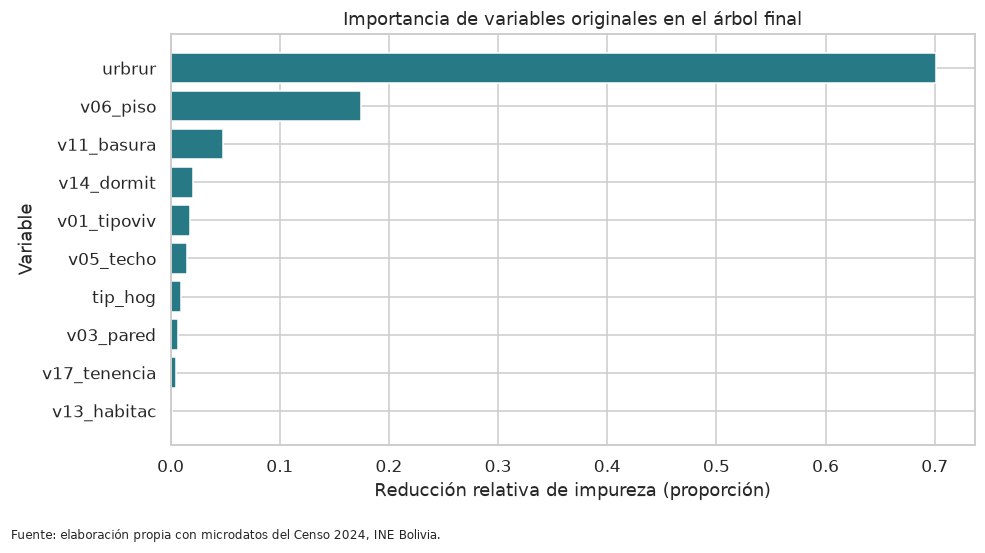

In [11]:
pre_arbol=modelo_arbol.named_steps["preprocesamiento"]
arbol=modelo_arbol.named_steps["clasificador"]
nombres_arbol=pre_arbol.get_feature_names_out()
importancias=arbol.feature_importances_
assert len(nombres_arbol)==len(importancias)
tabla_importancias=pd.DataFrame({"Categoría codificada":nombres_arbol,
                                 "Importancia":importancias}).sort_values("Importancia",ascending=False)
origen=[]
for nombre,categorias in zip(predictoras,pre_arbol.named_transformers_["categoricas"].categories_):
    origen.extend([nombre]*(len(categorias)-1))
assert len(origen)==len(importancias)
importancia_original=(pd.DataFrame({"Variable":origen,"Importancia":importancias})
    .groupby("Variable",as_index=False)["Importancia"].sum()
    .sort_values("Importancia",ascending=False))
display(tabla_importancias.head(15).round(5))
display(importancia_original.round(5))
fig,ax=plt.subplots(figsize=(9,5))
t=importancia_original.sort_values("Importancia")
ax.barh(t["Variable"],t["Importancia"],color="#267985")
ax.set(title="Importancia de variables originales en el árbol final",
       xlabel="Reducción relativa de impureza (proporción)",ylabel="Variable")
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()

In [12]:
top_arbol=importancia_original.iloc[0]
top_pos=tabla_coef.loc[tabla_coef["Coeficiente"].idxmax()]
top_neg=tabla_coef.loc[tabla_coef["Coeficiente"].idxmin()]
display(Markdown(
    f"#### Interpretación\n\nLa mayor importancia agregada del árbol corresponde a **`{top_arbol['Variable']}`** "
    f"({top_arbol['Importancia']:.4f}). Se obtuvo sumando las importancias de sus columnas One-Hot. "
    f"En la regresión, el coeficiente más positivo es **`{top_pos['Categoría codificada']}`** "
    f"({top_pos['Categoría oficial']}; {top_pos['Coeficiente']:+.4f}) y el más negativo es **`{top_neg['Categoría codificada']}`** "
    f"({top_neg['Categoría oficial']}; {top_neg['Coeficiente']:+.4f}). El signo compara con la categoría de referencia indicada "
    "en la tabla, manteniendo las demás columnas constantes. Ninguna de estas asociaciones prueba causalidad."
))

#### Interpretación

La mayor importancia agregada del árbol corresponde a **`urbrur`** (0.7014). Se obtuvo sumando las importancias de sus columnas One-Hot. En la regresión, el coeficiente más positivo es **`categoricas__v11_basura_4`** (La botan al río; +1.5128) y el más negativo es **`categoricas__v01_tipoviv_3`** (Departamento; -6.7103). El signo compara con la categoría de referencia indicada en la tabla, manteniendo las demás columnas constantes. Ninguna de estas asociaciones prueba causalidad.

### Pregunta 9. ¿Qué desempeño obtuvo el modelo en el conjunto de prueba? Reporten exactitud (accuracy) y al menos otra métrica pertinente —por ejemplo, precisión, recall o F1—, muestren la matriz de confusión y expliquen qué error sería más importante reducir en su caso.

#### Respuesta

La evaluación usa únicamente el conjunto de **prueba reservado** y toma la clase 1 como positiva. Para verdaderos positivos (VP), verdaderos negativos (VN), falsos positivos (FP) y falsos negativos (FN):

$$\mathrm{Accuracy}=\frac{VP+VN}{VP+VN+FP+FN},\quad
\mathrm{Precision}=\frac{VP}{VP+FP},\quad
\mathrm{Recall}=\frac{VP}{VP+FN},\quad
F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}.$$

ROC-AUC resume la discriminación a distintos umbrales. Un FN es una vivienda con dos o más carencias que el modelo clasifica como no precaria; puede quedar fuera de una revisión priorizada. Un FP implica revisar una vivienda que no pertenece a la clase positiva según la definición operativa. La importancia relativa de ambos errores depende del costo de la intervención.

#### Procedimiento y evidencia

In [13]:
def medir(nombre,modelo):
    pred=modelo.predict(X_test)
    prob=modelo.predict_proba(X_test)[:,1]
    m={"Modelo":nombre,
       "Accuracy":accuracy_score(y_test,pred),
       "Precision":precision_score(y_test,pred),
       "Recall":recall_score(y_test,pred),
       "F1":f1_score(y_test,pred),
       "ROC-AUC":roc_auc_score(y_test,prob)}
    return m,confusion_matrix(y_test,pred,labels=[0,1])

met_log,cm_log=medir("Regresión logística",modelo_logistico)
met_arbol,cm_arbol=medir("Árbol de decisión",modelo_arbol)
tabla_metricas=pd.DataFrame([met_log,met_arbol]).set_index("Modelo").T
tabla_metricas.index.name="Métrica"
display(tabla_metricas.round(4))
tabla_confusion=pd.DataFrame([{"Modelo":nombre,"TN":int(cm[0,0]),"FP":int(cm[0,1]),
                              "FN":int(cm[1,0]),"TP":int(cm[1,1])}
   for nombre,cm in [("Regresión logística",cm_log),("Árbol de decisión",cm_arbol)]])
display(tabla_confusion)
assert all(int(cm.sum())==len(y_test) for cm in (cm_log,cm_arbol))
assert abs(met_log["F1"]-0.7099)<0.0001
assert abs(met_arbol["F1"]-0.7061)<0.0001
assert np.array_equal(cm_log,[[366819,56914],[15148,88151]])
assert np.array_equal(cm_arbol,[[399803,23930],[33863,69436]])

Modelo,Regresión logística,Árbol de decisión
Métrica,,
Accuracy,0.8633,0.8903
Precision,0.6077,0.7437
Recall,0.8534,0.6722
F1,0.7099,0.7061
ROC-AUC,0.9303,0.9273


,Modelo,TN,FP,FN,TP
0,Regresión logística,366819,56914,15148,88151
1,Árbol de decisión,399803,23930,33863,69436


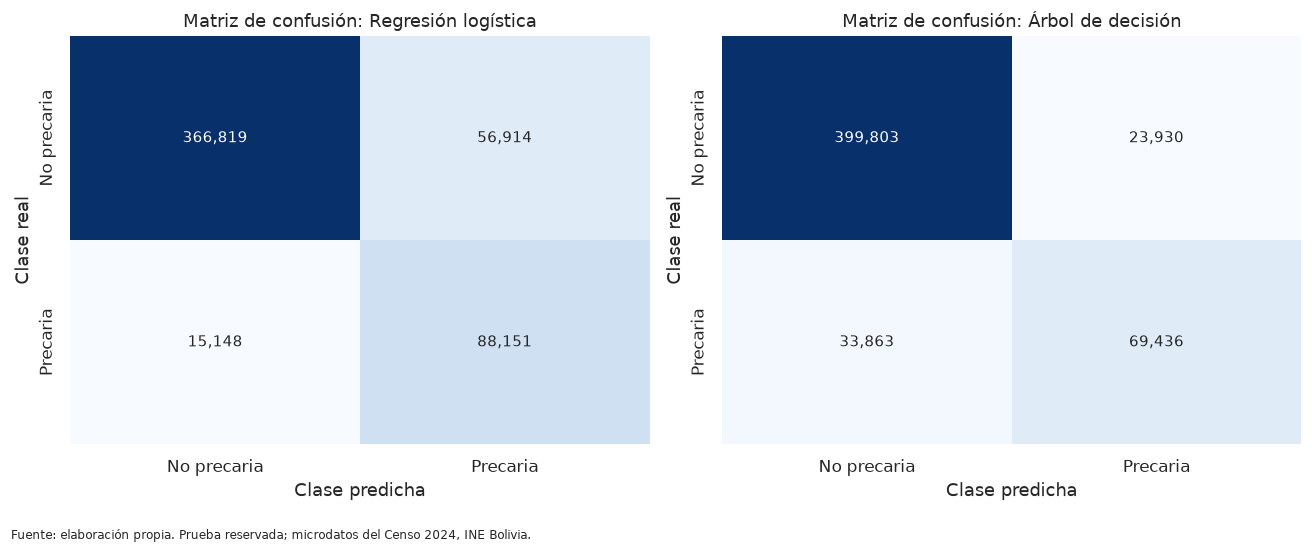

In [14]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,cm,nombre in zip(axes,[cm_log,cm_arbol],["Regresión logística","Árbol de decisión"]):
    sns.heatmap(cm,annot=True,fmt=",d",cmap="Blues",cbar=False,ax=ax,
                xticklabels=["No precaria","Precaria"],yticklabels=["No precaria","Precaria"])
    ax.set(title=f"Matriz de confusión: {nombre}",xlabel="Clase predicha",ylabel="Clase real")
fig.text(0.01,0.01,FUENTE_PRUEBA,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()

In [15]:
display(Markdown(
    f"#### Interpretación\n\nEn prueba, la regresión logística obtuvo **F1={met_log['F1']:.4f}** "
    f"y el árbol **F1={met_arbol['F1']:.4f}**. La primera dejó **{cm_log[1,0]:,} FN** "
    f"y el segundo **{cm_arbol[1,0]:,} FN**. Si el objetivo operativo es no omitir viviendas "
    "con carencias simultáneas, conviene estudiar el umbral de clasificación y el costo de revisar "
    "casos adicionales. Esa es una mejora propuesta: requeriría validación específica y no está "
    "demostrada por las métricas actuales. Ambos resultados corresponden a modelos finales y al mismo conjunto de prueba."
))

#### Interpretación

En prueba, la regresión logística obtuvo **F1=0.7099** y el árbol **F1=0.7061**. La primera dejó **15,148 FN** y el segundo **33,863 FN**. Si el objetivo operativo es no omitir viviendas con carencias simultáneas, conviene estudiar el umbral de clasificación y el costo de revisar casos adicionales. Esa es una mejora propuesta: requeriría validación específica y no está demostrada por las métricas actuales. Ambos resultados corresponden a modelos finales y al mismo conjunto de prueba.

### Pregunta 10. ¿Qué visualización permite entender cómo toma decisiones su modelo? Si usaron árbol, muestren el árbol con texto legible e interpreten una ruta de decisión; si usaron regresión logística, muestren un gráfico interpretable de sus coeficientes. Expliquen brevemente qué aporta la visualización.

#### Respuesta

Los primeros niveles del árbol muestran divisiones comprensibles, aunque la predicción utiliza el árbol completo. La ruta calculada para una vivienda real de prueba permite seguir las condiciones hasta una hoja. El gráfico de coeficientes logísticos muestra categorías asociadas con mayor o menor puntuación respecto a su categoría de referencia; no expresa un efecto causal.

#### Procedimiento y evidencia

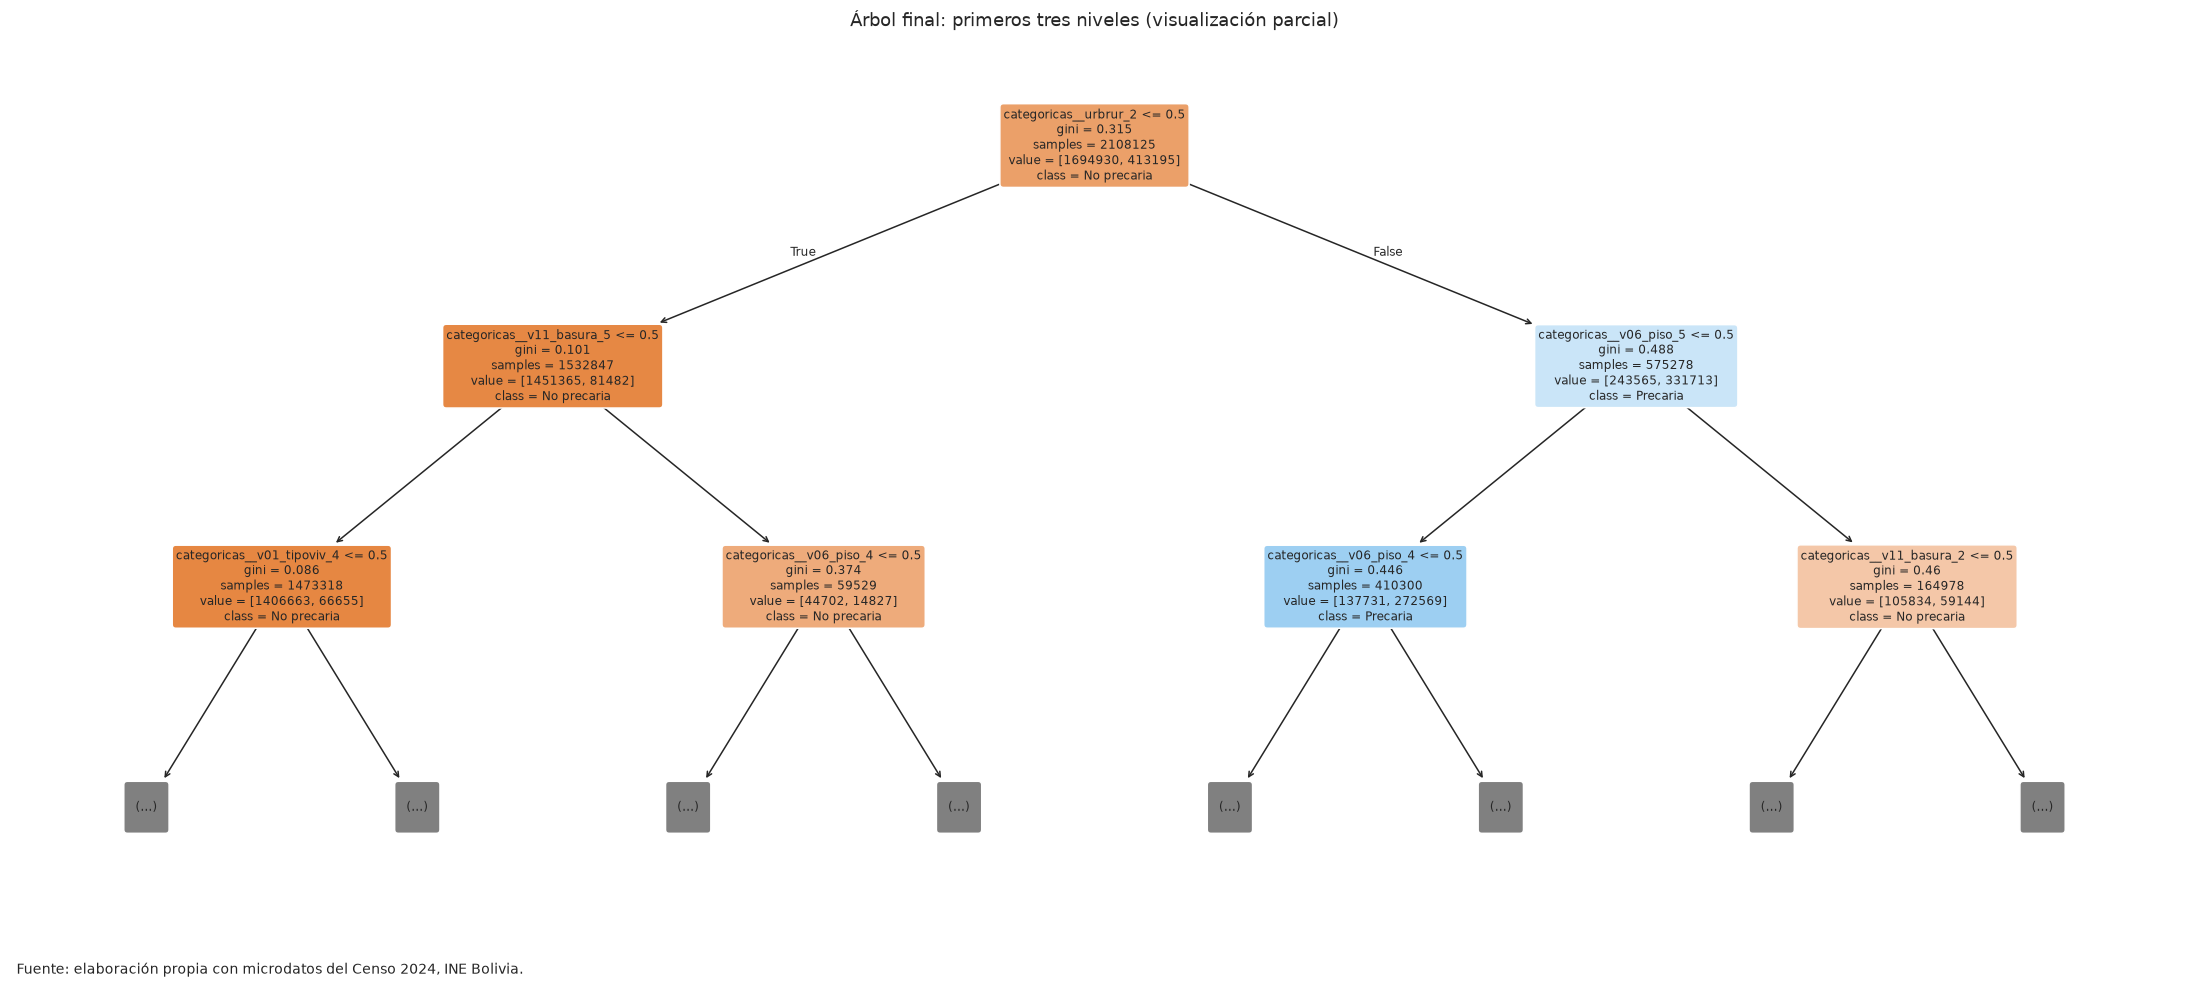

,Nodo,Variable,Código,Categoría oficial,Valor codificado,Comparación,Umbral
0,0,urbrur,2,Rural,0.0,≤,0.5
1,1,v11_basura,5,La queman,0.0,≤,0.5
2,2,v01_tipoviv,4,Cuarto(s) o habitación(es) suelta(s),0.0,≤,0.5
3,3,v14_dormit,1,Uno,0.0,≤,0.5
4,4,v01_tipoviv,5,Vivienda improvisada o vivienda móvil,0.0,≤,0.5
5,5,v01_tipoviv,6,Establecimiento no destinado para vivienda,0.0,≤,0.5
6,6,v06_piso,4,"Cerámica, porcelanato",1.0,>,0.5
7,56,v01_tipoviv,3,Departamento,0.0,≤,0.5
8,57,tip_hog,4,Hogar nuclear completo,1.0,>,0.5
9,149,v13_habitac,2,Dos,0.0,≤,0.5


Índice de vivienda de prueba: 2087807 | Hoja: 168 | Clase predicha: 0 | Puntuación clase 1: 0.0026 | Registros de entrenamiento en hoja: 24752


In [16]:
fig,ax=plt.subplots(figsize=(20,9))
plot_tree(arbol,max_depth=2,feature_names=nombres_arbol,
          class_names=["No precaria","Precaria"],filled=True,rounded=True,
          impurity=True,proportion=False,fontsize=8,ax=ax)
ax.set_title("Árbol final: primeros tres niveles (visualización parcial)")
fig.text(0.01,0.01,FUENTE,fontsize=9)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()
fila=X_test.iloc[[0]]
transformada=pre_arbol.transform(fila)
nodos=arbol.decision_path(transformada).indices
hoja=int(arbol.apply(transformada)[0])
reglas=[]
for nodo in nodos:
    if nodo==hoja: break
    j=int(arbol.tree_.feature[nodo]);umbral=float(arbol.tree_.threshold[nodo])
    valor=float(transformada[0,j]);operador="≤" if valor<=umbral else ">"
    variable,codigo,etiqueta=descomponer_categoria(nombres_arbol[j])
    reglas.append({"Nodo":int(nodo),"Variable":variable,"Código":codigo,
                   "Categoría oficial":etiqueta,"Valor codificado":valor,
                   "Comparación":operador,"Umbral":umbral})
display(pd.DataFrame(reglas))
clase_hoja=int(arbol.predict(transformada)[0])
prob_hoja=float(arbol.predict_proba(transformada)[0,1])
print("Índice de vivienda de prueba:",fila.index[0],"| Hoja:",hoja,
      "| Clase predicha:",clase_hoja,"| Puntuación clase 1:",round(prob_hoja,4),
      "| Registros de entrenamiento en hoja:",int(arbol.tree_.n_node_samples[hoja]))

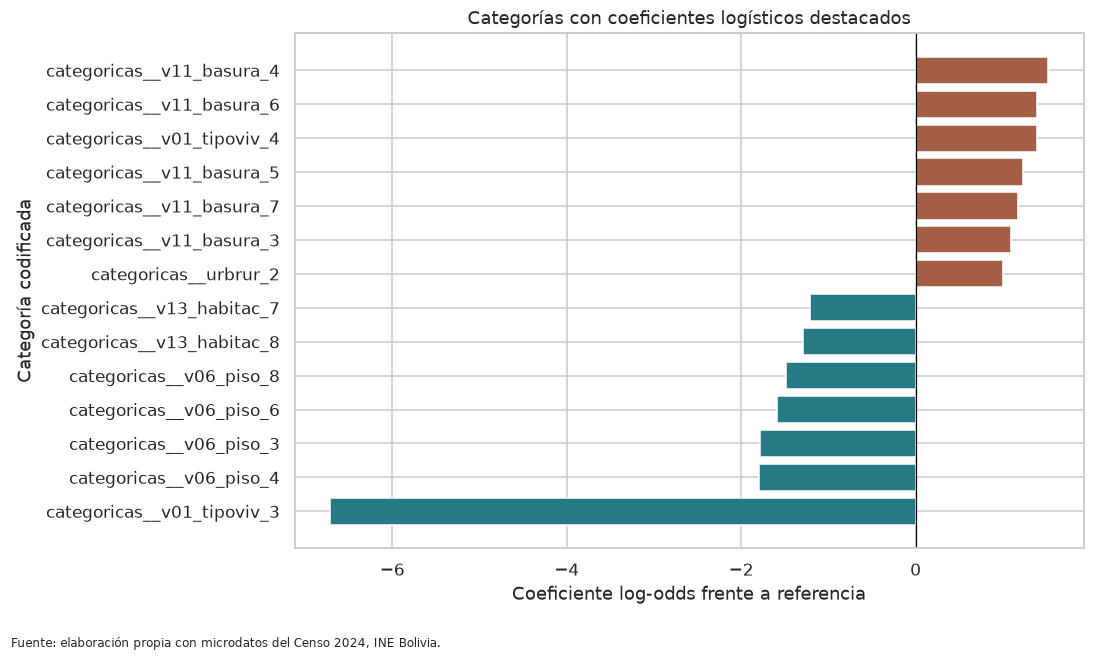

In [17]:
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(destacados["Categoría codificada"],destacados["Coeficiente"],
        color=np.where(destacados["Coeficiente"]>=0,"#a65f47","#267985"))
ax.axvline(0,color="black",linewidth=.8)
ax.set(title="Categorías con coeficientes logísticos destacados",
       xlabel="Coeficiente log-odds frente a referencia",ylabel="Categoría codificada")
fig.text(0.01,0.01,FUENTE,fontsize=8)
fig.tight_layout(rect=(0,0.05,1,1));plt.show()

In [18]:
display(Markdown(
    f"#### Interpretación\n\nLa vivienda de prueba con índice **{fila.index[0]}** sigue "
    f"**{len(reglas)} divisiones** hasta la hoja **{hoja}**. En cada fila de la tabla, el valor "
    "de la categoría One-Hot se compara con el umbral y se toma la rama indicada: 1 indica "
    "que la vivienda pertenece a esa categoría y 0 que no pertenece. "
    f"La hoja contiene **{arbol.tree_.n_node_samples[hoja]:,}** viviendas de entrenamiento "
    f"y predice la clase **{clase_hoja}** (puntuación de clase 1: **{prob_hoja:.4f}**). "
    "El dibujo muestra solo tres niveles del árbol entrenado; la ruta usa todos los niveles. "
    "En la regresión, barras positivas y negativas se interpretan frente a los códigos de referencia "
    "de la pregunta 8, manteniendo constantes las demás variables codificadas."
))

#### Interpretación

La vivienda de prueba con índice **2087807** sigue **15 divisiones** hasta la hoja **168**. En cada fila de la tabla, el valor de la categoría One-Hot se compara con el umbral y se toma la rama indicada: 1 indica que la vivienda pertenece a esa categoría y 0 que no pertenece. La hoja contiene **24,752** viviendas de entrenamiento y predice la clase **0** (puntuación de clase 1: **0.0026**). El dibujo muestra solo tres niveles del árbol entrenado; la ruta usa todos los niveles. En la regresión, barras positivas y negativas se interpretan frente a los códigos de referencia de la pregunta 8, manteniendo constantes las demás variables codificadas.

**Fuente de los datos:** Instituto Nacional de Estadística de Bolivia, *Censo de Población y Vivienda 2024*, microdatos del archivo `data/Vivienda_CPV-2024.csv` y diccionario oficial `data/Diccionario de variables CPV 2024.xlsx`. El IPS, las tablas, figuras y modelos son elaboraciones de este proyecto.